# Heart disease: preprocessing

This notebook applies the preprocessing decisions that came out of `01_data_exploration.ipynb` and saves a cleaned
copy of the data to `data/processed/heart_disease_clean.csv`. The raw CSV is never modified.

What happens here:
1. Load the raw CSV and apply the same cleaning as the EDA (missing tokens, number parsing, impossible zeros → missing).
2. Drop `slope`, `ca`, and `thal`.
3. Drop the rows that are missing 7 or more of the original 13 predictors.
4. Clip negative `oldpeak` values to 0.
5. Flag (but keep) near-duplicate pairs and per-hospital outliers.
6. Compare the data before and after, then save.

Anything that has to be *learned* from the data (filling in missing values, encoding, scaling) is left for the
modeling stage, so it can be fit on the training data only.

In [1]:
from pathlib import Path
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})

# Works when launched from the project root or notebooks directory.
data_path = next((parent / 'data/raw/heart_disease_uci.csv'
                  for parent in [Path.cwd(), *Path.cwd().parents]
                  if (parent / 'data/raw/heart_disease_uci.csv').is_file()), None)
if data_path is None:
    raise FileNotFoundError('Run this notebook from inside the VitalPipe project.')
processed_path = data_path.parents[1] / 'processed' / 'heart_disease_clean.csv'
raw_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
print('Raw CSV:', data_path.name)
print('SHA-256:', raw_sha256)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | Matplotlib {matplotlib.__version__}')

Raw CSV: heart_disease_uci.csv
SHA-256: 574f2fa2b43012fa25fca4fcdb36bd7c6bccdd0af4242f6c0e4c8633c5a072ae
Python 3.9.6 | pandas 2.3.3 | NumPy 2.0.2 | Matplotlib 3.9.4


**What this shows:** this cell only prints setup information. The first line is the raw file I'm working from. The
second line is its SHA-256 fingerprint, `574f2fa2…`. It's the same fingerprint as in the EDA notebook, so both
notebooks are looking at exactly the same data. The last line lists the software versions used for this run.

## 1. Load and apply the EDA cleaning rules

Same rules as the EDA notebook: blank/`?`-style tokens become missing, numbers and True/False columns are parsed,
and cholesterol or resting blood pressure of exactly 0 is treated as "not measured". The binary target
`disease_present` is `num > 0`; the original `num` is kept alongside it.

In [2]:
EXPECTED_COLUMNS = ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol',
                    'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope',
                    'ca', 'thal', 'num']
NUMERIC = ['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']
BOOLEAN = ['fbs', 'exang']
CATEGORIES = {
    'sex': ['Female', 'Male'],
    'dataset': ['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach'],
    'cp': ['typical angina', 'atypical angina', 'non-anginal', 'asymptomatic'],
    'restecg': ['normal', 'st-t abnormality', 'lv hypertrophy'],
    'slope': ['upsloping', 'flat', 'downsloping'],
    'thal': ['normal', 'fixed defect', 'reversable defect'],
}
MISSING_TOKENS = {'', '?', 'na', 'n/a', 'nan', 'null', 'none'}
SOURCES = CATEGORIES['dataset']
PREDICTORS_13 = [c for c in EXPECTED_COLUMNS if c not in ['id', 'dataset', 'num']]

raw = pd.read_csv(data_path, dtype='string', keep_default_na=False)
assert raw.columns.tolist() == EXPECTED_COLUMNS, 'Unexpected schema.'
tokens = raw.apply(lambda column: column.str.strip())
tokens = tokens.mask(tokens.apply(lambda column: column.str.lower().isin(MISSING_TOKENS)))

df = tokens.copy()
for column in NUMERIC:
    df[column] = pd.to_numeric(tokens[column], errors='raise').astype('float64')
for column in BOOLEAN:
    df[column] = tokens[column].str.upper().map({'TRUE': True, 'FALSE': False}).astype('boolean')
for column, allowed in CATEGORIES.items():
    assert df[column].dropna().isin(allowed).all(), f'Unknown category in {column}'
assert df['num'].isin([0, 1, 2, 3, 4]).all(), 'Unexpected target code.'
for column in ['id', 'age', 'num']:
    df[column] = df[column].astype('Int64')

zeros_set_missing = {column: int(df[column].le(0).sum()) for column in ['trestbps', 'chol']}
for column in zeros_set_missing:
    df.loc[df[column].le(0), column] = np.nan
df['disease_present'] = df['num'].gt(0)

before = df.copy()  # snapshot for before/after comparisons
display(pd.Series(zeros_set_missing, name='zero values set to missing').to_frame())
display(df.head())
print(f'{len(df):,} rows × {df.shape[1]} columns (16 original + disease_present)')

,zero values set to missing
trestbps,1
chol,172


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,disease_present
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,False
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,True
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,True
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,False
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,False


920 rows × 17 columns (16 original + disease_present)


**What this shows, from top to bottom:**

**The first table** counts the values of exactly 0 that I turned into "missing". There were **172 cholesterol values
and 1 resting blood pressure value**. Nobody can have a cholesterol of 0 or a blood pressure of 0, so these were never
real measurements. Most likely the test wasn't done and a 0 was typed in as a placeholder.

**The second table** shows the first 5 patients after cleaning. Each row is one patient. The last column,
`disease_present`, is the new yes/no target. It is `True` whenever `num` is 1–4 and `False` when `num` is 0.
For example, patient 2 has `num = 2`, so `disease_present = True`.

**The line at the bottom** confirms all 920 patients are still here. There are 17 columns: the original 16 plus
`disease_present`.

<sub>Numbers above come from the run on the raw CSV with SHA-256 `574f2fa2…`; re-check them if the data changes.</sub>

## 2. Drop `slope`, `ca`, and `thal`

These three predictors had the most missing values in the EDA.

In [3]:
DROPPED_COLUMNS = ['slope', 'ca', 'thal']
display(before[DROPPED_COLUMNS].isna().mean().mul(100)
        .rename('missing_pct_before_drop').to_frame())
df = df.drop(columns=DROPPED_COLUMNS)
PREDICTORS = [c for c in PREDICTORS_13 if c not in DROPPED_COLUMNS]
print(f'Remaining candidate predictors ({len(PREDICTORS)}):', ', '.join(PREDICTORS))

,missing_pct_before_drop
slope,33.587
ca,66.413
thal,52.826


Remaining candidate predictors (10): age, sex, cp, trestbps, chol, fbs, restecg, thalch, exang, oldpeak


**What this shows:**

**The table** shows how much of each dropped column was missing before I removed it.
`ca` was missing for **66%** of patients, `thal` for **53%**, and `slope` for **34%**. For most patients, these tests
simply weren't recorded.

**The line underneath** lists the 10 candidate predictors that are left:
age, sex, chest pain type, resting blood pressure, cholesterol, fasting blood sugar, resting ECG, max heart rate,
exercise-induced chest pain, and oldpeak.

<sub>Numbers above come from the run on the raw CSV with SHA-256 `574f2fa2…`; re-check them if the data changes.</sub>

## 3. Drop near-empty rows

A row is dropped when 7 or more of the **original 13** predictors are missing (counted before the column drop,
matching the EDA's completeness chart).

In [4]:
NEAR_EMPTY_THRESHOLD = 7
missing_13 = before[PREDICTORS_13].isna().sum(axis=1)
near_empty = missing_13.ge(NEAR_EMPTY_THRESHOLD)

display(before.loc[near_empty, 'dataset'].value_counts().reindex(SOURCES, fill_value=0)
        .rename('rows_dropped').to_frame())
display(before.loc[near_empty, PREDICTORS_13].isna().sum()
        .rename('missing_among_dropped_rows').to_frame())
display(before.loc[near_empty, 'disease_present'].value_counts()
        .rename('rows_dropped').rename_axis('disease_present').to_frame())

df = df.loc[~near_empty].copy()
print(f'{int(near_empty.sum())} rows dropped; {len(df)} rows remain.')

,rows_dropped
dataset,
Cleveland,0
Hungary,0
Switzerland,1
VA Long Beach,53


,missing_among_dropped_rows
age,0
sex,0
cp,0
trestbps,54
chol,13
fbs,0
restecg,0
thalch,54
exang,54
oldpeak,54


,rows_dropped
disease_present,
True,35
False,19


54 rows dropped; 866 rows remain.


**What this shows, from top to bottom:**

**The first table** shows which hospital the dropped rows came from. **53 of the 54 are from VA Long Beach** and 1 is
from Switzerland. Cleveland and Hungary lost no rows.

**The second table** shows what those 54 rows were missing. Every one of them was missing **resting blood pressure,
max heart rate, exercise chest pain, oldpeak, slope, and ca**. Almost all were also missing `thal` (52 of 54).
Apart from age, sex, chest pain type, fasting blood sugar, and resting ECG, these patients had almost no measurements.

**The third table** shows the diagnosis of the dropped rows: **35 had heart disease and 19 did not**.

**The last line** confirms the result: 54 rows removed, **866 rows remain**.

<sub>Numbers above come from the run on the raw CSV with SHA-256 `574f2fa2…`; re-check them if the data changes.</sub>

## 4. Clip negative `oldpeak` to 0

After this step `oldpeak` means "how much the ECG line dropped during exercise", with 0 meaning no drop.
The affected rows are shown with their original and new values.

In [5]:
negative_oldpeak = df['oldpeak'].lt(0)
oldpeak_changes = (df.loc[negative_oldpeak, ['id', 'dataset', 'oldpeak', 'num']]
                   .rename(columns={'oldpeak': 'original_oldpeak'}))
df['oldpeak'] = df['oldpeak'].clip(lower=0)
oldpeak_changes.insert(3, 'clipped_oldpeak', df.loc[negative_oldpeak, 'oldpeak'])
display(oldpeak_changes)
print(f'{int(negative_oldpeak.sum())} oldpeak values clipped to 0; '
      f'{int(df["oldpeak"].isna().sum())} oldpeak values are still missing (not filled in).')

,id,dataset,original_oldpeak,clipped_oldpeak,num
603,604,Switzerland,-1.1,0.0,0
609,610,Switzerland,-1.5,0.0,1
614,615,Switzerland,-0.1,0.0,0
615,616,Switzerland,-2.6,0.0,1
629,630,Switzerland,-0.7,0.0,2
653,654,Switzerland,-2.0,0.0,2
655,656,Switzerland,-1.0,0.0,1
656,657,Switzerland,-1.0,0.0,2
691,692,Switzerland,-0.8,0.0,1
694,695,Switzerland,-0.5,0.0,1


12 oldpeak values clipped to 0; 8 oldpeak values are still missing (not filled in).


**What this shows:**

**The table** lists every patient whose `oldpeak` was negative, with the original value next to the new clipped value.
There were **12 such patients**: 11 from Switzerland and 1 from VA Long Beach. The values ranged from −0.1 to −2.6,
and all of them are now 0.
The `num` column shows their diagnosis. 9 of the 12 had heart disease (`num` 1 or 2) and 3 did not.

`oldpeak` measures how far the ECG line drops during exercise. A negative value means the line went *up* instead.
After clipping, `oldpeak` only measures drops, and anything that wasn't a drop counts as 0.

**The line underneath** says 12 values were clipped, and that **8 oldpeak values are still missing**. Those 8 are left
empty here on purpose. Filling them in happens at the modeling stage.

<sub>Numbers above come from the run on the raw CSV with SHA-256 `574f2fa2…`; re-check them if the data changes.</sub>

## 5. Flags: near-duplicate pairs and per-hospital outliers

Nothing is removed in this step; flag columns are added for review and for keeping matched records together later.

- `near_dup_group`: records identical to another record in every original column except `id` share a group number.
- `outlier_<feature>`: True when the value falls outside that **hospital's** Tukey fences (`Q1 − 1.5×IQR`,
  `Q3 + 1.5×IQR`). No fence is computed when a hospital has fewer than 4 observed values or zero IQR.

In [6]:
# Near-duplicates are matched on the original record (before column drop and clipping).
record_columns = [c for c in EXPECTED_COLUMNS if c != 'id']
kept_original = before.loc[df.index, record_columns]
record_key = kept_original.astype('string').fillna('<NA>').agg('|'.join, axis=1)
is_near_dup = record_key.duplicated(keep=False)
df['near_dup_group'] = pd.Series(pd.NA, index=df.index, dtype='Int64')
df.loc[is_near_dup, 'near_dup_group'] = pd.factorize(record_key[is_near_dup])[0] + 1
display(df.loc[is_near_dup, ['near_dup_group', 'id', 'dataset', 'age', 'sex', 'cp',
                             'trestbps', 'chol', 'thalch', 'num']].sort_values(['near_dup_group', 'id']))

CONTINUOUS = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
FLAG_COLUMNS = [f'outlier_{feature}' for feature in CONTINUOUS]
fence_rows = []
for feature in CONTINUOUS:
    df[f'outlier_{feature}'] = False
for source in SOURCES:
    in_source = df['dataset'].eq(source)
    for feature in CONTINUOUS:
        observed = df.loc[in_source, feature].dropna()
        q1, q3 = observed.quantile([.25, .75]) if len(observed) else (np.nan, np.nan)
        iqr = q3 - q1
        usable = len(observed) >= 4 and pd.notna(iqr) and iqr > 0
        lower, upper = (q1 - 1.5 * iqr, q3 + 1.5 * iqr) if usable else (np.nan, np.nan)
        if usable:
            values = df.loc[in_source, feature]
            df.loc[in_source, f'outlier_{feature}'] = (values.lt(lower) | values.gt(upper)).to_numpy()
        fence_rows.append({'dataset': source, 'feature': feature, 'observed_n': len(observed),
                           'lower_fence': lower, 'upper_fence': upper,
                           'flagged_n': int(df.loc[in_source, f'outlier_{feature}'].sum()),
                           'status': 'computed' if usable else 'no fence (insufficient data / zero IQR)'})
fences = pd.DataFrame(fence_rows).set_index(['dataset', 'feature'])
display(fences)

flag_counts = df.groupby('dataset')[FLAG_COLUMNS].sum().reindex(SOURCES)
flag_counts.loc['All hospitals'] = flag_counts.sum()
display(flag_counts.astype(int))
any_flag = df[FLAG_COLUMNS].any(axis=1)
print(f'{int(is_near_dup.sum())} rows in {int(df["near_dup_group"].max())} near-duplicate groups; '
      f'{int(any_flag.sum())} rows have at least one outlier flag. All rows are kept.')

,near_dup_group,id,dataset,age,sex,cp,trestbps,chol,thalch,num
404,1,405,Hungary,49,Female,atypical angina,110.0,NaN,160.0,0
405,1,406,Hungary,49,Female,atypical angina,110.0,NaN,160.0,0
859,2,860,VA Long Beach,58,Male,non-anginal,150.0,219.0,118.0,2
907,2,908,VA Long Beach,58,Male,non-anginal,150.0,219.0,118.0,2


observed_n  lower_fence  upper_fence  flagged_n  \
dataset       feature                                                     
Cleveland     age              304       27.875       80.875          0   
              trestbps         304       90.000      170.000          9   
              chol             304      115.000      371.000          5   
              thalch           304       85.375      214.375          1   
              oldpeak          304       -2.400        4.000          5   
Hungary       age              293       24.000       72.000          0   
              trestbps         292       90.000      170.000          8   
              chol             270       99.000      393.000         10   
              thalch           292       72.500      204.500          0   
              oldpeak          293       -1.500        2.500         11   
Switzerland   age              122       36.000       76.000          3   
              trestbps         121       70.000      190.000          2   
              chol               0          NaN          NaN          0   
              thalch           122       50.625      193.625          0   
              oldpeak          117       -2.250        3.750          0   
VA Long Beach age              147       43.000       75.000          9   
              trestbps         143       78.000      190.000          0   
              chol             103      125.500      349.500          3   
              thalch           147       62.500      186.500          0   
              oldpeak          144       -3.000        5.000          0   

                                                         status  
dataset       feature                                            
Cleveland     age                                      computed  
              trestbps                                 computed  
              chol                                     computed  
              thalch                                   computed  
              oldpeak                                  computed  
Hungary       age                                      computed  
              trestbps                                 computed  
              chol                                     computed  
              thalch                                   computed  
              oldpeak                                  computed  
Switzerland   age                                      computed  
              trestbps                                 computed  
              chol      no fence (insufficient data / zero IQR)  
              thalch                                   computed  
              oldpeak                                  computed  
VA Long Beach age                                      computed  
              trestbps                                 computed  
              chol                                     computed  
              thalch                                   computed  
              oldpeak                                  computed

,outlier_age,outlier_trestbps,outlier_chol,outlier_thalch,outlier_oldpeak
dataset,,,,,
Cleveland,0,9,5,1,5
Hungary,0,8,10,0,11
Switzerland,3,2,0,0,0
VA Long Beach,9,0,3,0,0
All hospitals,12,19,18,1,16


4 rows in 2 near-duplicate groups; 65 rows have at least one outlier flag. All rows are kept.


**What this shows, from top to bottom:**

**The first table** shows the near-duplicate pairs. These are records identical in every original column except the
ID. There are **2 pairs**:
- **Group 1:** patients 405 and 406 from Hungary. Their IDs are back to back.
- **Group 2:** patients 860 and 908 from VA Long Beach.

Within each pair, the diagnosis is the same. I kept all four rows and gave each pair a shared `near_dup_group` number,
so I can tell which records belong together.

**The second (long) table** shows the outlier fences, worked out **separately for each hospital**. For each
hospital and measurement it shows how many values were available (`observed_n`), the low and high cut-offs
(`lower_fence`, `upper_fence`), and how many values fell outside them (`flagged_n`). Some things stand out:
- **Hospitals have different "normal" ranges.** Hungary's oldpeak cut-off is 2.5, so its 11 flags are values above
  2.5. At VA Long Beach the cut-off is 5.0 and nothing is flagged.
- **VA Long Beach has 9 age flags.** Its patients are mostly older, so the youngest ones look unusual within that hospital.
- **Switzerland has no cholesterol fence**, because it has no cholesterol values at all (`observed_n` = 0). Its
  cholesterol flags are all False.
- Swiss oldpeak has no flags. The clipping in the previous step happened before the fences were worked out, so the
  old negative values are now 0 and sit inside the fence.

**The third table** totals the flags per hospital. Across all hospitals: **19 blood pressure, 18 cholesterol,
16 oldpeak, 12 age, and 1 max heart rate**.

**The last line** sums it up: 4 rows in 2 near-duplicate groups, and **65 rows with at least one outlier flag**.
No row was removed. The flags only mark values for me to review.

<sub>Numbers above come from the run on the raw CSV with SHA-256 `574f2fa2…`; re-check them if the data changes.</sub>

## 6. Before vs. after

"Before" is the full dataset with all 13 predictors (after zeros → missing). "After" is the processed dataset
with 10 predictors. A complete row has every predictor filled in.

before (13 predictors)                                         \
                                rows disease_pct complete_rows complete_pct   
dataset                                                                       
Cleveland                      304.0      45.724         297.0       97.697   
Hungary                        293.0      36.177           1.0        0.341   
Switzerland                    123.0      93.496           0.0        0.000   
VA Long Beach                  200.0      74.500           1.0        0.500   
All hospitals                  920.0      55.326         299.0       32.500   

              after (10 predictors)                                         
                               rows disease_pct complete_rows complete_pct  
dataset                                                                     
Cleveland                     304.0      45.724         304.0      100.000  
Hungary                       293.0      36.177         260.0       88.737  
Switzerland                   122.0      93.443           0.0        0.000  
VA Long Beach                 147.0      78.231          97.0       65.986  
All hospitals                 866.0      54.734         661.0       76.328

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak
dataset,,,,,,,,,,
Cleveland,0.0,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Hungary,0.0,0.0,0.0,0.341,7.850,2.730,0.341,0.341,0.341,0.000
Switzerland,0.0,0.0,0.0,0.820,100.000,61.475,0.820,0.000,0.000,4.098
VA Long Beach,0.0,0.0,0.0,2.721,29.932,4.762,0.000,0.000,0.000,2.041
All hospitals,0.0,0.0,0.0,0.693,21.824,10.393,0.231,0.115,0.115,0.924


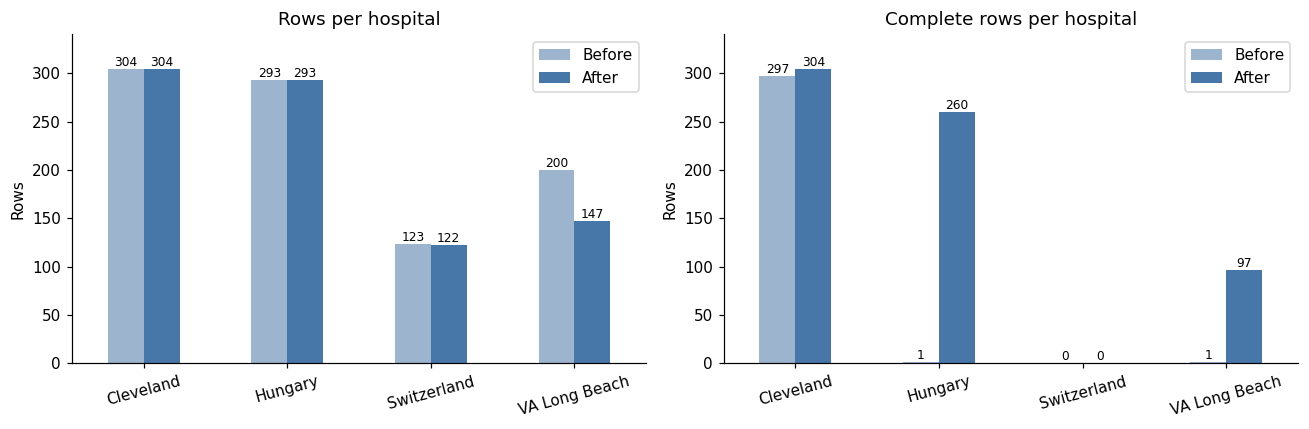

In [7]:
def summarize(frame, predictors):
    complete = frame[predictors].notna().all(axis=1)
    by_source = pd.DataFrame({
        'rows': frame.groupby('dataset').size(),
        'disease_pct': frame.groupby('dataset')['disease_present'].mean().mul(100),
        'complete_rows': complete.groupby(frame['dataset']).sum(),
    }).reindex(SOURCES).astype('float64')
    by_source.loc['All hospitals'] = [len(frame), frame['disease_present'].mean() * 100, complete.sum()]
    by_source['complete_pct'] = by_source['complete_rows'].div(by_source['rows']).mul(100)
    return by_source

before_summary = summarize(before, PREDICTORS_13)
after_summary = summarize(df, PREDICTORS)
impact = pd.concat({'before (13 predictors)': before_summary,
                    'after (10 predictors)': after_summary}, axis=1)
display(impact)

missing_after = df[PREDICTORS].isna().groupby(df['dataset']).mean().mul(100).reindex(SOURCES)
missing_after.loc['All hospitals'] = df[PREDICTORS].isna().mean().mul(100)
display(missing_after)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, title in zip(axes, ['rows', 'complete_rows'],
                             ['Rows per hospital', 'Complete rows per hospital']):
    pd.DataFrame({'Before': before_summary.loc[SOURCES, column],
                  'After': after_summary.loc[SOURCES, column]}).plot.bar(
        ax=ax, rot=15, color=['#9db4cf', '#4776a8'])
    ax.set(title=title, ylabel='Rows', xlabel='')
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', fontsize=8)
    ax.margins(y=0.12)
fig.tight_layout()
plt.show()

**What this shows, from top to bottom:**

**The first table** compares each hospital before and after preprocessing:
- **Rows:** only VA Long Beach changed much (200 → 147). Switzerland lost 1 row (123 → 122). Cleveland and
  Hungary are unchanged.
- **Disease rate:** overall it barely moved (55.3% → 54.7%). VA Long Beach went from 74.5% to 78.2%. The 53 VA rows
  that were dropped had a lower disease rate (34 of 53, about 64%) than VA as a whole, so the remaining VA patients
  are slightly more likely to have disease. The other hospitals are essentially unchanged.
- **Complete rows** (every predictor filled in) went from **299 (32.5%) to 661 (76.3%)**. Before, almost every complete
  row was from Cleveland. Now Hungary has 260 complete rows (89%), VA Long Beach has 97 (66%), and Cleveland is
  at 100%. **Switzerland still has 0**, because none of its patients have cholesterol.

**The second table** shows the % still missing in each of the 10 predictors, per hospital:
- **Cholesterol is the biggest remaining gap:** 22% overall. It is 100% missing in Switzerland, 30% at VA Long Beach,
  and 8% in Hungary.
- **Fasting blood sugar** is next: 10% overall, almost all of it in Switzerland (61%).
- Everything else is under 1% missing overall.
- Cleveland has nothing missing at all.

**The bar charts** show the first table visually:
- **Left chart (rows per hospital):** the light bar is before and the dark bar is after. The only visible drop is
  VA Long Beach, from 200 to 147.
- **Right chart (complete rows per hospital):** this is the biggest change. Hungary goes from 1 to 260 complete rows
  and VA Long Beach from 1 to 97. Before, almost all complete data came from Cleveland. Now three of the four
  hospitals have mostly complete records. Switzerland stays at 0 because of cholesterol.

<sub>Numbers above come from the run on the raw CSV with SHA-256 `574f2fa2…`; re-check them if the data changes.</sub>

## 7. Save the processed dataset

In [8]:
OUTPUT_COLUMNS = ['id', 'dataset', *PREDICTORS, 'num', 'disease_present', 'near_dup_group', *FLAG_COLUMNS]
clean = df[OUTPUT_COLUMNS].reset_index(drop=True)

# Consistency checks before writing.
assert len(clean) == len(before) - int(near_empty.sum())
assert not set(DROPPED_COLUMNS) & set(clean.columns)
assert clean['oldpeak'].dropna().ge(0).all()
assert clean['chol'].dropna().gt(0).all() and clean['trestbps'].dropna().gt(0).all()
assert clean['id'].is_unique
assert clean['disease_present'].eq(clean['num'].gt(0)).all()

processed_path.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(processed_path, index=False)
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == raw_sha256, 'Raw CSV changed!'

display(pd.DataFrame({'dtype': clean.dtypes.astype(str),
                      'missing_n': clean.isna().sum()}))
print(f'Saved {len(clean):,} rows × {clean.shape[1]} columns to data/processed/{processed_path.name}')
print('Raw CSV unchanged (SHA-256 verified).')

,dtype,missing_n
id,Int64,0
dataset,string,0
age,Int64,0
sex,string,0
cp,string,0
trestbps,float64,6
chol,float64,189
fbs,boolean,90
restecg,string,2
thalch,float64,1


Saved 866 rows × 20 columns to data/processed/heart_disease_clean.csv
Raw CSV unchanged (SHA-256 verified).


**What this shows:**

**The table** lists every column in the saved file, with its data type and how many values are missing:
- The **10 predictors** still have some gaps: cholesterol 189, fasting blood sugar 90, oldpeak 8, resting blood
  pressure 6, resting ECG 2, max heart rate 1, and exercise chest pain 1.
- `id`, `dataset`, `num`, and `disease_present` have no gaps.
- `near_dup_group` shows 862 "missing". That's expected: only the 4 near-duplicate rows have a group number.
- The 5 `outlier_` columns are True/False flags with no gaps.

**The last two lines** confirm the cleaned data (**866 rows × 20 columns**) was saved to
`data/processed/heart_disease_clean.csv`, and that the original raw CSV was not changed.

<sub>Numbers above come from the run on the raw CSV with SHA-256 `574f2fa2…`; re-check them if the data changes.</sub>